
# Student Academic State-Transition Model

## Stochastic Processes – Project 1

**Project Topic:** Modeling Student Academic Conditions Using a Hidden Markov Model (HMM)

**Course:** Stochastic Processes

**Project:** Project 1

**Team Members:**
- Student 1: [Mostafa Ashraf ELShrief – 2401248097 ]
- Student 2: [Mostafa Mahmoud Mohamadeen – 2401244790 ]
- Student 3: [Ahmed Hassan Mohamed Hassan – 2401247856 ]
- Student 4: [Ahmed Mohamed Said Ali – 2401244297 ]
- Student 5: [Ziad Reda Ahmed Salama – 2401246225 ]


## 1. Project Introduction

This project presents a probabilistic model for analyzing changes in students' academic conditions over time using a Hidden Markov Model (HMM).

Students may experience different academic conditions during their studies, such as being focused, distracted, or burned out. These conditions may change from one week to another.

Since these internal conditions cannot be observed directly, the model uses observable academic outcomes, such as high scores, average scores, and low or missed scores, to represent the evidence associated with each hidden condition.

The project aims to model these changes mathematically and analyze the behavior of the system over time.



## 2. Problem Definition

The problem addressed in this project is modeling the evolution of a student's academic condition over consecutive weeks.

A student's academic performance may be influenced by their underlying condition, which can change over time.

We consider three possible academic conditions:

1. Focused
2. Distracted
3. Burned Out

The model assumes that the student's condition changes according to probabilistic transition rules.

Because the actual academic condition is not directly observable, the model uses academic performance outcomes as observations.

The system is modeled on a weekly basis, where each transition represents a possible change in the student's condition from one week to the next.



## 3. Hidden States and Observation Symbols

### 3.1 Hidden States

The model contains three hidden states:

| State | Description |
|---|---|
| Focused | The student is in a focused academic condition and is assumed to be actively engaged in studying. |
| Distracted | The student experiences reduced concentration and inconsistent academic engagement. |
| Burned Out | The student experiences a condition of academic exhaustion that may negatively affect academic engagement. |

These states are considered hidden because the student's internal academic condition cannot be measured directly.

### 3.2 Observation Symbols

The model considers three possible observable outcomes:

| Observation | Description |
|---|---|
| High Score | The student achieves a high academic score. |
| Average Score | The student achieves an average academic score. |
| Low / Missed | The student achieves a low score or misses an academic assessment. |

These observations provide indirect information about the student's underlying academic condition.

**Important:** The observation symbols are not the hidden states. They represent measurable outcomes associated with the hidden states.



## 4. Markov Property Justification

The Markov property states that the probability of the next state depends only on the current state and not on the complete sequence of previous states.

Mathematically:

P(Xₙ₊₁ = j | Xₙ = i, Xₙ₋₁, ..., X₀)
=
P(Xₙ₊₁ = j | Xₙ = i)

In this project, the model assumes that the probability of a student's academic condition in the next week depends on their current academic condition.

For example, if a student is currently in the Focused state, the probabilities of remaining Focused, becoming Distracted, or becoming Burned Out depend on the current state.

This assumption simplifies the modeling process by representing the evolution of academic conditions using a transition matrix.

The Markov property is a modeling assumption and does not imply that previous academic history has no real-world influence. Instead, its effects are assumed to be summarized by the current state.


In [60]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch


## 5. Model Assumptions

The transition probabilities in this project are based on illustrative assumptions rather than an experimentally collected student dataset.

The model assumes that:

1. A student can occupy one of three academic states at a given week.
2. The student's academic condition may change from one week to another.
3. The transition probabilities depend only on the current state.
4. The transition probabilities remain constant over time.
5. Each transition matrix row represents the possible next states from the current state.
6. The probabilities in each row must sum to one.

The selected transition probabilities are illustrative and are used to demonstrate the mathematical properties of the model.


In [61]:

# ==========================================
# R1 & R2: Model Definition
# ==========================================

STATES = ["Focused", "Distracted", "Burned Out"]

OBSERVATIONS = [
    "High Score",
    "Average Score",
    "Low / Missed"
]

# Transition Matrix P
P = np.array([
    [0.70, 0.20, 0.10],  # From Focused
    [0.30, 0.50, 0.20],  # From Distracted
    [0.20, 0.35, 0.45]   # From Burned Out
])

print("States:", STATES)
print("Observations:", OBSERVATIONS)

print("\nTransition Matrix P:")
print(P)


States: ['Focused', 'Distracted', 'Burned Out']
Observations: ['High Score', 'Average Score', 'Low / Missed']

Transition Matrix P:
[[0.7  0.2  0.1 ]
 [0.3  0.5  0.2 ]
 [0.2  0.35 0.45]]



## 6. Transition Matrix (P)

The transition matrix describes the probabilities of moving from one hidden state to another in one time step (one week).

The rows represent the current states, while the columns represent the next states.

The transition matrix is:

P =

| Current State | Focused | Distracted | Burned Out |
|---|---:|---:|---:|
| Focused | 0.70 | 0.20 | 0.10 |
| Distracted | 0.30 | 0.50 | 0.20 |
| Burned Out | 0.20 | 0.35 | 0.45 |

For example:

- P(Focused → Focused) = 0.70
- P(Focused → Distracted) = 0.20
- P(Focused → Burned Out) = 0.10

This means that if a student is currently Focused, the model assigns a 70% probability of remaining Focused in the following week.

Similarly, if the student is currently Burned Out, the probability of remaining in that state during the next week is 45%.



## 7. Justification of Transition Probabilities

The transition probabilities are based on reasonable illustrative assumptions about changes in academic conditions.

The selected values reflect the following assumptions:

- Focused students have a relatively high probability of remaining Focused.
- Focused students may become Distracted or Burned Out, but these transitions are assigned lower probabilities.
- Distracted students have a reasonable chance of returning to a Focused condition.
- Distracted students may remain Distracted or transition to Burned Out.
- Burned Out students have a relatively high probability of remaining in that condition, while recovery to Focused is possible.

These assumptions are represented numerically in the transition matrix.

The values are illustrative and do not represent measured probabilities from a real student population.



## 8. Transition Matrix Validation

A valid transition matrix must satisfy two main conditions:

1. Every matrix entry must be between 0 and 1.
2. The sum of the probabilities in each row must equal 1.

Mathematically:

0 ≤ Pᵢⱼ ≤ 1

Σⱼ Pᵢⱼ = 1

These conditions ensure that each row represents a valid probability distribution over the possible next states.


In [62]:

# ==========================================
# Verify Transition Matrix
# ==========================================

def verify_transition_matrix(matrix, state_names):

    print("Transition Matrix P:")
    print(matrix)

    print("\nVerification:")

    # Check non-negativity and upper bound
    valid_bounds = np.all(
        (matrix >= 0) & (matrix <= 1)
    )

    print(f"- All entries in [0, 1]: {valid_bounds}")

    # Check row sums equal 1
    row_sums = matrix.sum(axis=1)

    for name, total in zip(state_names, row_sums):
        print(f"- Row sum for '{name}': {total:.2f}")

    all_rows_sum_to_one = np.allclose(row_sums, 1.0)

    print(f"- Every row sums to 1: {all_rows_sum_to_one}")

    assert valid_bounds and all_rows_sum_to_one, \
        "Invalid transition matrix!"

    print("\nTransition Matrix is valid!")


verify_transition_matrix(P, STATES)


Transition Matrix P:
[[0.7  0.2  0.1 ]
 [0.3  0.5  0.2 ]
 [0.2  0.35 0.45]]

Verification:
- All entries in [0, 1]: True
- Row sum for 'Focused': 1.00
- Row sum for 'Distracted': 1.00
- Row sum for 'Burned Out': 1.00
- Every row sums to 1: True

Transition Matrix is valid!



## 9. State-Transition Diagram

The State-Transition Diagram provides a visual representation of the Markov transition matrix.

Each node represents one hidden state, and each directed arrow represents a possible transition between two states.

The probability displayed on each arrow corresponds to the transition probability between the associated states.

Self-loops represent the probability of remaining in the same state during the next week.

The diagram helps visualize the possible movements between the three academic conditions.


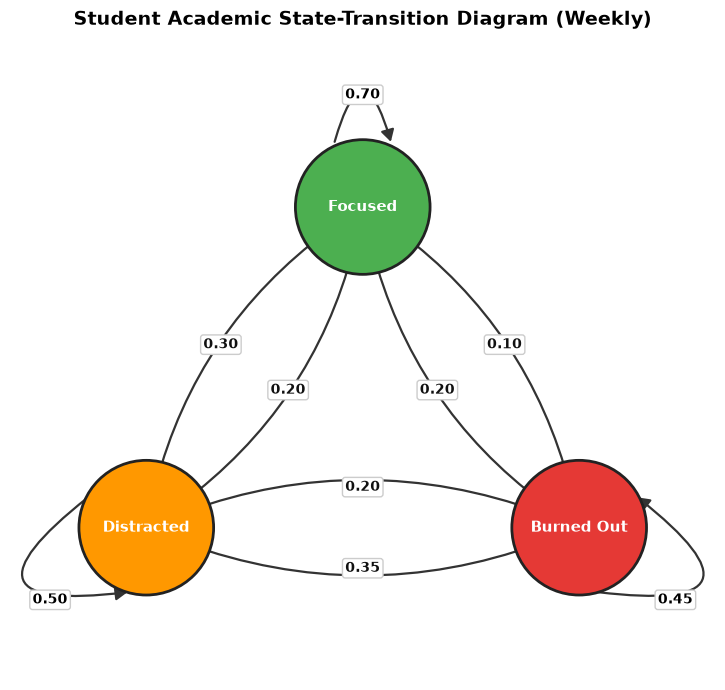


Saved diagram to state_transition_diagram.png


In [63]:

# ==========================================
# Draw State-Transition Diagram
# ==========================================

def draw_transition_diagram(
    matrix,
    state_names,
    filename="state_transition_diagram.png"
):

    fig, ax = plt.subplots(figsize=(9, 7))

    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-1.8, 2.2)

    ax.set_aspect("equal")
    ax.axis("off")

    # Node positions
    positions = {
        0: (0.0, 1.15),
        1: (-1.35, -0.85),
        2: (1.35, -0.85)
    }

    colors = ["#4CAF50", "#FF9800", "#E53935"]

    radius = 0.42

    # Draw nodes
    for i, name in enumerate(state_names):

        x, y = positions[i]

        circle = Circle(
            (x, y),
            radius,
            facecolor=colors[i],
            edgecolor="#222222",
            linewidth=2,
            zorder=3
        )

        ax.add_patch(circle)

        ax.text(
            x, y, name,
            ha="center",
            va="center",
            color="white",
            fontsize=11,
            fontweight="bold",
            zorder=4
        )

    # Draw curved edges
    def draw_edge(i, j, prob, rad=0.18, label_offset=(0, 0)):

        x1, y1 = positions[i]
        x2, y2 = positions[j]

        arrow = FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            connectionstyle=f"arc3,rad={rad}",
            arrowstyle="-|>,head_length=8,head_width=5",
            shrinkA=radius * 72,
            shrinkB=radius * 72,
            color="#333333",
            linewidth=1.6,
            zorder=2
        )

        ax.add_patch(arrow)

        mx, my = (x1 + x2) / 2, (y1 + y2) / 2

        dx, dy = x2 - x1, y2 - y1

        dist = np.hypot(dx, dy)

        nx, ny = -dy / dist, dx / dist

        lx = mx + nx * (rad * 1.15) + label_offset[0]
        ly = my + ny * (rad * 1.15) + label_offset[1]

        ax.text(
            lx, ly,
            f"{prob:.2f}",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="#111111",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="#cccccc"
            )
        )

    # Draw all off-diagonal transitions
    for i in range(len(state_names)):

        for j in range(len(state_names)):

            if i != j and matrix[i, j] > 0:

                draw_edge(
                    i, j,
                    matrix[i, j],
                    rad=0.22
                )

    # Draw self-loops
    loop_configs = {
        0: ((0.0, 1.85), (-0.18, 1.54), (0.18, 1.54), -1.8),
        1: ((-1.95, -1.30), (-1.70, -0.65), (-1.45, -1.25), 1.8),
        2: ((1.95, -1.30), (1.45, -1.25), (1.70, -0.65), 1.8),
    }

    for i, (label_pos, start, end, rad) in loop_configs.items():

        if matrix[i, i] > 0:

            loop = FancyArrowPatch(
                start,
                end,
                connectionstyle=f"arc3,rad={rad}",
                arrowstyle="-|>,head_length=7,head_width=4",
                color="#333333",
                linewidth=1.6,
                zorder=2
            )

            ax.add_patch(loop)

            ax.text(
                label_pos[0],
                label_pos[1],
                f"{matrix[i, i]:.2f}",
                ha="center",
                va="center",
                fontsize=10,
                fontweight="bold",
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    facecolor="white",
                    edgecolor="#cccccc"
                )
            )

    plt.title(
        "Student Academic State-Transition Diagram (Weekly)",
        fontsize=14,
        fontweight="bold",
        pad=10
    )

    plt.tight_layout()

    plt.savefig(filename, dpi=300)

    plt.show()

    print(f"\nSaved diagram to {filename}")


draw_transition_diagram(P, STATES)



## 10. Part A Summary

In this part, we defined the student academic model and established its transition structure.

The model includes:

- Three hidden academic states.
- Three observation symbols.
- A 3 × 3 transition matrix.
- A verification function to validate the transition matrix.
- A State-Transition Diagram showing the possible transitions.

The transition matrix provides the mathematical foundation for analyzing the system's behavior over multiple time steps.

The next part of the project will use this matrix to investigate n-step transition probabilities and the long-run steady-state distribution.


# Part B – R3 + R4: n-Step Analysis and Steady-State Distribution

This section analyzes the **hidden-state Markov chain** defined in Part A. It focuses on how the probabilities of the three academic states evolve over time.

We will study:

- **π₀ (Initial Distribution):** The probability distribution of students' academic states at the starting week.
- **Pⁿ (n-Step Transition Matrix):** The transition probabilities after n weeks.
- **π* (Steady-State Distribution):** The long-run probability distribution that the Markov chain approaches over time.

**Scope note:** R3 and R4 analyze the hidden-state transition matrix **P** only. The observation/emission matrix **E**, Forward algorithm, and Viterbi algorithm are covered in the later HMM sections by the other team members.

The analysis uses the transition matrix P defined in Part A.

In [64]:
import pandas as pd

# Display the transition matrix with state labels
P_df = pd.DataFrame(
    P,
    index=STATES,
    columns=STATES
)

print("Transition Matrix P:")
display(P_df)

print("\nState Order:")
for i, state in enumerate(STATES):
    print(f"{i}: {state}")

Transition Matrix P:


,Focused,Distracted,Burned Out
Focused,0.7,0.20,0.10
Distracted,0.3,0.50,0.20
Burned Out,0.2,0.35,0.45



State Order:
0: Focused
1: Distracted
2: Burned Out


## B1. Initial Probability Distribution (π₀)

The initial distribution π₀ represents the probabilities of students being in each academic state at the beginning of the observation period.

Since the project does not currently use collected student data to estimate the starting proportions, we choose an **illustrative starting distribution** for demonstrating the Markov-chain calculations.

For this example, we use π₀ = [0.50, 0.30, 0.20]:

- 50% Focused
- 30% Distracted
- 20% Burned Out

These simple proportions provide a clear example in which all three states have a non-zero starting probability. They are an assumption for the model demonstration, **not percentages measured from real students**.

The probabilities must satisfy two conditions:

1. Every probability must be non-negative.
2. The sum of all probabilities must equal 1.

The initial distribution will be used to calculate the state distribution in future weeks.

In [65]:
# Define the initial probability distribution
pi_0 = np.array([0.50, 0.30, 0.20])

# Display the initial distribution
pi_0_df = pd.DataFrame({
    "State": STATES,
    "Initial Probability": pi_0
})

display(pi_0_df)

# Verify the initial distribution
print("Initial Distribution Verification:")

non_negative = np.all(pi_0 >= 0)
sum_is_one = np.isclose(np.sum(pi_0), 1.0)

print(f"All probabilities are non-negative: {non_negative}")
print(f"Sum of probabilities = {np.sum(pi_0):.2f}")
print(f"Sum equals 1: {sum_is_one}")

assert non_negative and sum_is_one, "Invalid initial probability distribution!"

,State,Initial Probability
0,Focused,0.5
1,Distracted,0.3
2,Burned Out,0.2


Initial Distribution Verification:
All probabilities are non-negative: True
Sum of probabilities = 1.00
Sum equals 1: True


## B2. n-Step Transition Probabilities

The n-step transition matrix, denoted by Pⁿ, represents the probabilities of moving from one academic state to another after n weeks.

For example:

- P¹ represents transitions after one week.
- P² represents transitions after two weeks.
- P³ represents transitions after three weeks.

The n-step transition matrix is calculated using matrix multiplication:

Pⁿ = P × P × ... × P

where P is multiplied by itself n times.

### Chapman–Kolmogorov Equation

The Chapman–Kolmogorov equation states that:

P⁽ⁿ⁺ᵐ⁾ = Pⁿ × Pᵐ

This means that the probability of moving between two states over multiple steps can be calculated by combining transition probabilities across intermediate steps.

In our project, this allows us to study how students' academic states may change over several weeks.

Each entry Pⁿ[i,j] represents the probability that a student starting in state i will be in state j after n weeks.

Every row of Pⁿ must sum to 1 because the student must be in one of the defined states after n weeks.

In [66]:
# Calculate the 2-step transition matrix
P2 = np.linalg.matrix_power(P, 2)

# Display P^2
P2_df = pd.DataFrame(
    P2,
    index=STATES,
    columns=STATES
)

print("2-Step Transition Matrix (P^2):")
display(P2_df)

# Verify that each row sums to 1
print("Row sums:", P2.sum(axis=1))
assert np.allclose(P2.sum(axis=1), 1.0)

print("P^2 is a valid stochastic matrix.")

2-Step Transition Matrix (P^2):


,Focused,Distracted,Burned Out
Focused,0.570,0.2750,0.1550
Distracted,0.400,0.3800,0.2200
Burned Out,0.335,0.3725,0.2925


Row sums: [1. 1. 1.]
P^2 is a valid stochastic matrix.


In [67]:
# Calculate the 3-step transition matrix
P3 = np.linalg.matrix_power(P, 3)

# Display P^3
P3_df = pd.DataFrame(
    P3,
    index=STATES,
    columns=STATES
)

print("3-Step Transition Matrix (P^3):")
display(P3_df)

# Verify that each row sums to 1
print("Row sums:", P3.sum(axis=1))
assert np.allclose(P3.sum(axis=1), 1.0)

print("P^3 is a valid stochastic matrix.")

3-Step Transition Matrix (P^3):


,Focused,Distracted,Burned Out
Focused,0.51250,0.305750,0.181750
Distracted,0.43800,0.347000,0.215000
Burned Out,0.40475,0.355625,0.239625


Row sums: [1. 1. 1.]
P^3 is a valid stochastic matrix.


In [68]:
# Choose a large number of steps
n = 50

# Calculate P^n
Pn = np.linalg.matrix_power(P, n)

# Display P^n
Pn_df = pd.DataFrame(
    Pn,
    index=STATES,
    columns=STATES
)

print(f"{n}-Step Transition Matrix (P^{n}):")
display(Pn_df)

# Verify stochastic matrix properties
print("\nRow sums:", Pn.sum(axis=1))
assert np.allclose(Pn.sum(axis=1), 1.0)

# Chapman-Kolmogorov verification:
# P^(2+3) = P^2 × P^3
P5_direct = np.linalg.matrix_power(P, 5)
P5_combined = P2 @ P3

print("\nChapman-Kolmogorov Verification:")
print("P^5 calculated directly:")
display(pd.DataFrame(P5_direct, index=STATES, columns=STATES))

print("P^2 × P^3:")
display(pd.DataFrame(P5_combined, index=STATES, columns=STATES))

print(
    "Are both results equal?",
    np.allclose(P5_direct, P5_combined)
)

50-Step Transition Matrix (P^50):


,Focused,Distracted,Burned Out
Focused,0.465909,0.329545,0.204545
Distracted,0.465909,0.329545,0.204545
Burned Out,0.465909,0.329545,0.204545



Row sums: [1. 1. 1.]

Chapman-Kolmogorov Verification:
P^5 calculated directly:


,Focused,Distracted,Burned Out
Focused,0.475311,0.324824,0.199864
Distracted,0.460485,0.332398,0.207117
Burned Out,0.453232,0.335704,0.211064


P^2 × P^3:


,Focused,Distracted,Burned Out
Focused,0.475311,0.324824,0.199864
Distracted,0.460485,0.332398,0.207117
Burned Out,0.453232,0.335704,0.211064


Are both results equal? True


## B3. Interpretation of n-Step Transition Results

Comparing **P, P², P³, and P⁵⁰** shows how the transition probabilities change as the number of weeks increases.

Some numerical examples from the matrices are:

- **Focused → Focused:** the probability decreases from 0.70 after one week to 0.57 after two weeks, 0.5125 after three weeks, and approximately 0.4659 after 50 weeks.
- **Burned Out → Focused:** the probability increases from 0.20 after one week to 0.335 after two weeks, 0.40475 after three weeks, and approximately 0.4659 after 50 weeks.

The rows of P⁵⁰ are nearly identical. This means that after many weeks, the predicted state distribution becomes almost independent of the student's starting state.

For the chosen initial distribution, the proportion in the Focused state changes from **50% at week 0 to 46.86% at week 3**. This happens because the illustrative starting distribution assigns a higher proportion to Focused than the long-run distribution does.

These results show the chain moving toward a stable long-run pattern. The values are outputs of the assumed transition matrix, not measurements of actual student outcomes.

In [69]:
# Calculate weekly distributions using two methods

weekly_distributions = [pi_0]

for week in range(1, 4):
    # Method 1: Previous distribution multiplied by P
    next_distribution = weekly_distributions[-1] @ P
    weekly_distributions.append(next_distribution)

# Display weeks 0–3 and the large-n distribution at week 50
results = []

for week in range(4):
    # Method 2: Initial distribution multiplied by P^n
    direct_distribution = pi_0 @ np.linalg.matrix_power(P, week)
    recursive_distribution = weekly_distributions[week]

    results.append({
        "Week": week,
        "Focused": recursive_distribution[0],
        "Distracted": recursive_distribution[1],
        "Burned Out": recursive_distribution[2],
        "Sum": recursive_distribution.sum(),
        "Methods Match": np.allclose(recursive_distribution, direct_distribution)
    })

# Large-n distribution: pi_50 = pi_0 P^50
pi_50 = pi_0 @ np.linalg.matrix_power(P, 50)

results.append({
    "Week": 50,
    "Focused": pi_50[0],
    "Distracted": pi_50[1],
    "Burned Out": pi_50[2],
    "Sum": pi_50.sum(),
    "Methods Match": np.allclose(pi_50, pi_0 @ np.linalg.matrix_power(P, 50))
})

weekly_df = pd.DataFrame(results)

print("State distributions at weeks 0–3 and week 50:")
display(weekly_df)

print("All displayed distributions sum to 1:",
      np.allclose(weekly_df["Sum"], 1.0))

assert weekly_df["Methods Match"].all()
assert np.allclose(weekly_df["Sum"], 1.0)

print("\nWeek 50 distribution (pi_50):", np.round(pi_50, 6))

State distributions at weeks 0–3 and week 50:


,Week,Focused,Distracted,Burned Out,Sum,Methods Match
0,0,0.500000,0.300000,0.200000,1.0,True
1,1,0.480000,0.320000,0.200000,1.0,True
2,2,0.472000,0.326000,0.202000,1.0,True
3,3,0.468600,0.328100,0.203300,1.0,True
4,50,0.465909,0.329545,0.204545,1.0,True


All displayed distributions sum to 1: True

Week 50 distribution (pi_50): [0.465909 0.329545 0.204545]


In [70]:
# Select specific transition probabilities
selected_steps = [1, 2, 3, 5, 10, 50]

selected_results = []

for step in selected_steps:
    Pn_selected = np.linalg.matrix_power(P, step)

    selected_results.append({
        "Steps": step,
        "Focused -> Focused": Pn_selected[0, 0],
        "Focused -> Burned Out": Pn_selected[0, 2],
        "Distracted -> Focused": Pn_selected[1, 0],
        "Burned Out -> Focused": Pn_selected[2, 0]
    })

selected_df = pd.DataFrame(selected_results)

display(selected_df.round(6))

,Steps,Focused -> Focused,Focused -> Burned Out,Distracted -> Focused,Burned Out -> Focused
0,1,0.700000,0.100000,0.300000,0.200000
1,2,0.570000,0.155000,0.400000,0.335000
2,3,0.512500,0.181750,0.438000,0.404750
3,5,0.475311,0.199864,0.460485,0.453232
4,10,0.466082,0.204459,0.465810,0.465674
5,50,0.465909,0.204545,0.465909,0.465909


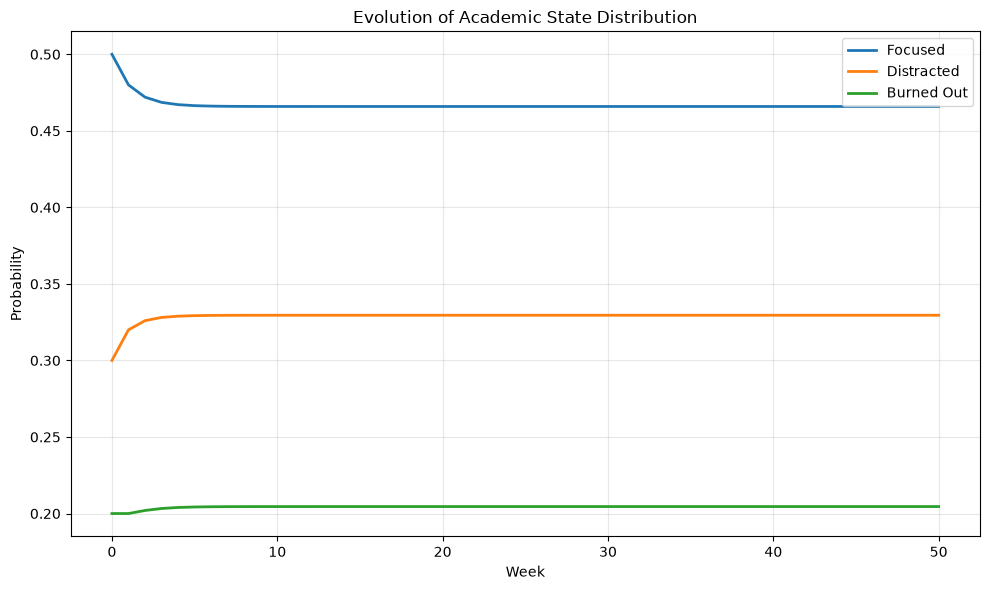

In [71]:
# Calculate distributions for 50 weeks
num_weeks = 50
distributions = [pi_0]

for week in range(num_weeks):
    distributions.append(distributions[-1] @ P)

distributions = np.array(distributions)

# Plot the evolution of state probabilities
plt.figure(figsize=(10, 6))

for i, state in enumerate(STATES):
    plt.plot(
        range(num_weeks + 1),
        distributions[:, i],
        label=state,
        linewidth=2
    )

plt.xlabel("Week")
plt.ylabel("Probability")
plt.title("Evolution of Academic State Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## B4. R3 – Weekly Distribution and Convergence Plot

The weekly distributions are calculated using πₙ = π₀Pⁿ. The table above compares the initial weeks with week 50, while the plot below shows how the probabilities evolve across all 50 weeks.

The curves approach stable values over time. This visual behavior is consistent with the convergence observed in the rows of P⁵⁰.

## B5. R4 – Steady-State Distribution

The steady-state distribution, denoted by π*, represents the long-run probability distribution of the Markov chain.

It describes the proportion of students expected to be in each academic state after a sufficiently large number of weeks.

The steady-state distribution satisfies:

π*P = π*

It must also satisfy the probability conditions:

1. All probabilities are non-negative.
2. The sum of all probabilities equals 1.

Therefore, we solve the following system:

π*P = π*

π*₁ + π*₂ + π*₃ = 1

The resulting distribution will help us understand the expected long-run proportions of students in the Focused, Distracted, and Burned Out states.

In [72]:
# Solve for the steady-state distribution
# We need: pi_star @ P = pi_star
# Equivalent to: (P.T - I) @ pi_star.T = 0

A = P.T - np.eye(len(STATES))

# Replace the last equation with the normalization condition
A[-1, :] = np.ones(len(STATES))

b = np.zeros(len(STATES))
b[-1] = 1

pi_star = np.linalg.solve(A, b)

# Display the steady-state distribution
steady_state_df = pd.DataFrame({
    "State": STATES,
    "Steady-State Probability": pi_star
})

display(steady_state_df)

# Verify the solution
print("Steady-State Verification:")
print("Sum of probabilities:", pi_star.sum())
print("All probabilities non-negative:", np.all(pi_star >= 0))
print("pi* × P:", pi_star @ P)
print("pi*:", pi_star)

assert np.allclose(pi_star.sum(), 1.0)
assert np.all(pi_star >= 0)
assert np.allclose(pi_star @ P, pi_star)

print("\nSteady-state distribution verified successfully!")

,State,Steady-State Probability
0,Focused,0.465909
1,Distracted,0.329545
2,Burned Out,0.204545


Steady-State Verification:
Sum of probabilities: 1.0
All probabilities non-negative: True
pi* × P: [0.46590909 0.32954545 0.20454545]
pi*: [0.46590909 0.32954545 0.20454545]

Steady-state distribution verified successfully!


## B6. Interpretation of Long-Run Proportions

The calculated steady-state distribution is approximately:

- **Focused:** 46.59%
- **Distracted:** 32.95%
- **Burned Out:** 20.45%

Under this model, these values describe the long-run proportions of time that a student-state process spends in each state. Equivalently, for a sufficiently large population of students following the same transition probabilities, they describe the expected proportions in each state after the system has reached its long-run behavior.

**Important limitation:** These percentages are mathematical outputs of the illustrative transition matrix P. They are **not measured statistics or empirical predictions about real students**, because the transition probabilities and initial distribution were assumed rather than estimated from collected student data.

For this irreducible and aperiodic chain, the steady-state distribution is unique. Consequently, the long-run distribution does not depend on the chosen initial distribution, even though the short-term distributions do.

In [73]:
# Compare P^50 rows with the steady-state distribution

differences = np.abs(Pn - pi_star)

comparison_df = pd.DataFrame(
    Pn,
    index=STATES,
    columns=STATES
)

print("P^50:")
display(comparison_df)

print("Maximum absolute difference for each starting state:")

for i, state in enumerate(STATES):
    max_diff = np.max(differences[i])
    print(f"{state}: {max_diff:.2e}")

overall_max_diff = np.max(differences)

print("\nOverall Maximum Absolute Difference:")
print(f"{overall_max_diff:.2e}")

assert overall_max_diff < 1e-8

print("\nP^50 has converged to the steady-state distribution.")

P^50:


,Focused,Distracted,Burned Out
Focused,0.465909,0.329545,0.204545
Distracted,0.465909,0.329545,0.204545
Burned Out,0.465909,0.329545,0.204545


Maximum absolute difference for each starting state:
Focused: 5.55e-16
Distracted: 4.44e-16
Burned Out: 5.55e-16

Overall Maximum Absolute Difference:
5.55e-16

P^50 has converged to the steady-state distribution.


## B7. Conditions for Convergence

A finite Markov chain converges to a unique steady-state distribution if it is irreducible and aperiodic.

### 1. Irreducibility

A Markov chain is irreducible if every state can eventually be reached from every other state.

In our model, all transition probabilities are positive. Therefore, every state can directly reach every other state in one step.

Thus, the chain is irreducible.

### 2. Aperiodicity

A Markov chain is aperiodic if its states do not follow a fixed repeating cycle.

In our model, every state has a positive self-transition probability:

- Focused → Focused = 0.70
- Distracted → Distracted = 0.50
- Burned Out → Burned Out = 0.45

These self-transitions allow the chain to remain in the same state, making the period of each state equal to 1.

Thus, the chain is aperiodic.

### Conclusion

Since the Markov chain is finite, irreducible, and aperiodic, it has a unique steady-state distribution, and its n-step transition probabilities converge to that distribution.

In [74]:
# Calculate eigenvalues and eigenvectors of P.T
eigenvalues, eigenvectors = np.linalg.eig(P.T)

# Find the eigenvector corresponding to eigenvalue 1
steady_index = np.argmin(np.abs(eigenvalues - 1))

steady_eigenvector = np.real(eigenvectors[:, steady_index])

# Normalize the eigenvector
pi_eigen = steady_eigenvector / np.sum(steady_eigenvector)

# Display the result
eigen_df = pd.DataFrame({
    "State": STATES,
    "Linear System Method": pi_star,
    "Eigenvector Method": pi_eigen
})

display(eigen_df)

# Compare both methods
eigen_difference = np.max(np.abs(pi_star - pi_eigen))

print("Maximum difference between methods:")
print(f"{eigen_difference:.12f}")

assert np.allclose(pi_star, pi_eigen)

print("Both methods produce the same steady-state distribution.")

,State,Linear System Method,Eigenvector Method
0,Focused,0.465909,0.465909
1,Distracted,0.329545,0.329545
2,Burned Out,0.204545,0.204545


Maximum difference between methods:
0.000000000000
Both methods produce the same steady-state distribution.


## B8. Final Summary – R3 + R4

In this section, we analyzed the short-term and long-term behavior of the student academic-state Markov chain.

### R3 – n-Step Analysis

- Calculated P², P³, and P⁵⁰ to study transitions over multiple weeks.
- Verified the Chapman–Kolmogorov equation: P⁵ = P²P³.
- Calculated weekly state distributions using πₙ = π₀Pⁿ.
- For the illustrative initial distribution, the Focused proportion changes from 50% at week 0 to 46.86% at week 3.
- The rows of P⁵⁰ become nearly identical, and π₀P⁵⁰ is approximately [0.465909, 0.329545, 0.204545].

### R4 – Steady-State Analysis

- Solved the steady-state equation π*P = π*.
- Verified that all probabilities are non-negative and sum to 1.
- Confirmed the result using P⁵⁰ and the eigenvector method.
- Established that the chain is irreducible and aperiodic.

### Final Steady-State Distribution

| Academic State | Long-Run Probability |
|---|---:|
| Focused | 46.59% |
| Distracted | 32.95% |
| Burned Out | 20.45% |

### Overall Conclusion

Under the assumed transition matrix, the Markov chain approaches the unique steady-state distribution shown above, regardless of its initial distribution.

**Model limitation:** The transition matrix and initial distribution are illustrative assumptions. Therefore, the percentages are theoretical model outputs and should not be interpreted as measured statistics about real students.

## R5: Absorption Analysis

In [75]:
# ==========================================
# R5: Absorption Analysis (Burned Out made absorbing)
# ==========================================

# Absorbing variant of P (used for R5 only)
P_abs = P.copy()
P_abs[2] = [0, 0, 1]
assert np.allclose(P_abs.sum(axis=1), 1.0), "Invalid absorbing matrix!"

# States are already ordered: transient first, absorbing last
print("Canonical form of P_abs = [[Q, R], [0, I]]  (transient first, Burned Out last):")
display(pd.DataFrame(P_abs, index=STATES, columns=STATES))

transient = STATES[:2]
absorbing = STATES[2:]

# Canonical form blocks
Q = P_abs[:2, :2]   # transient -> transient
R = P_abs[:2, 2:]   # transient -> absorbing

print("Q:")
display(pd.DataFrame(Q, index=transient, columns=transient))
print("R:")
display(pd.DataFrame(R, index=transient, columns=absorbing))

# Fundamental matrix
N = np.linalg.inv(np.eye(2) - Q)
print("N = (I - Q)^-1:")
display(pd.DataFrame(N, index=transient, columns=transient))

# Absorption probabilities
B = N @ R
print("B = N R:")
display(pd.DataFrame(B, index=transient, columns=absorbing))

# Expected steps to burnout
t = N @ np.ones(2)
print("Expected weeks until Burned Out (t = N 1):")
display(pd.DataFrame({"Expected Weeks": t}, index=transient))

# Verification
assert np.allclose(B.sum(axis=1), 1.0)
assert np.allclose(t, N.sum(axis=1))
print("R5 verified: each row of B sums to 1 and t equals the row sums of N.")

Canonical form of P_abs = [[Q, R], [0, I]]  (transient first, Burned Out last):


,Focused,Distracted,Burned Out
Focused,0.7,0.2,0.1
Distracted,0.3,0.5,0.2
Burned Out,0.0,0.0,1.0


Q:


,Focused,Distracted
Focused,0.7,0.2
Distracted,0.3,0.5


R:


,Burned Out
Focused,0.1
Distracted,0.2


... (3 outputs left out)

,Burned Out
Focused,1.0
Distracted,1.0


Expected weeks until Burned Out (t = N 1):


,Expected Weeks
Focused,7.777778
Distracted,6.666667


R5 verified: each row of B sums to 1 and t equals the row sums of N.


## R6 & R7: Hidden Markov Model Parameters and Forward Algorithm

In this section, we extend the project's Markov chain formulation into a *Hidden Markov Model (HMM)* so that unobservable student study states can be linked to observable academic outcomes across time. To stay consistent with the earlier sections of the notebook, we reuse the shared state definitions and transition dynamics (STATES and P) and introduce the emission structure (E).

### Core HMM Definitions and Alignment with Earlier Sections

The hidden states (STATES) are Focused, Distracted, and Burned Out, representing the latent study states of a student that are not directly observed. The observable outcomes (OBSERVATIONS) are High Score, Average Score, and Low / Missed, representing the recorded performance results at each step.

The initial state distribution (pi_0) is [0.50, 0.30, 0.20], matching the initial distribution used earlier in the project and indicating higher initial likelihood of starting in Focused. The transition matrix (P) is aligned with the transition probabilities from the preceding sections (with a fallback definition only if the cell is run standalone), ensuring full compatibility across team components.

### Emission Matrix (E) Design and Validation

The emission matrix E gives the conditional probability of observing each outcome given the current hidden state, where every row is non-negative and sums to 1.00:

- For Focused ([0.70, 0.20, 0.10]), probabilities lean strongly toward High Score (0.70), with smaller chances for Average Score (0.20) and Low / Missed (0.10).
- For Distracted ([0.25, 0.45, 0.30]), probabilities center around Average Score (0.45), alongside moderate chances for Low / Missed (0.30) and High Score (0.25).
- For Burned Out ([0.10, 0.25, 0.65]), probabilities skew heavily toward Low / Missed (0.65), with lower chances for Average Score (0.25) and High Score (0.10).

We also include assert checks to verify that pi_0 sums to 1.0 and that every row of both P and E sums to 1.0.

> *Note:* The probabilities in E are illustrative domain assumptions created for modeling and demonstration in this project rather than empirical measurements from real students.

In [76]:

# R6: Define hidden states, observations, initial distribution, and emission matrix
STATES = ["Focused", "Distracted", "Burned Out"]
OBSERVATIONS = ["High Score", "Average Score", "Low / Missed"]

obs_to_idx = {obs: idx for idx, obs in enumerate(OBSERVATIONS)}

pi_0 = np.array([0.50, 0.30, 0.20])

# Ensure P is available from earlier cells; fallback definition if running cell standalone
if "P" not in globals():
    P = np.array([
        [0.70, 0.20, 0.10],
        [0.30, 0.50, 0.20],
        [0.20, 0.35, 0.45]
    ])

E = np.array([
    [0.70, 0.20, 0.10],
    [0.25, 0.45, 0.30],
    [0.10, 0.25, 0.65]
])

assert np.isclose(pi_0.sum(), 1.0), "pi_0 must sum to 1."
assert np.allclose(P.sum(axis=1), 1.0), "Each row of P must sum to 1."
assert np.allclose(E.sum(axis=1), 1.0), "Each row of E must sum to 1."
E_df = pd.DataFrame(E, index=STATES, columns=OBSERVATIONS)
print("Emission Matrix E:")
display(E_df)


Emission Matrix E:


,High Score,Average Score,Low / Missed
Focused,0.70,0.20,0.10
Distracted,0.25,0.45,0.30
Burned Out,0.10,0.25,0.65


## R7. Forward Algorithm and Observation Sequence Probability

With the HMM parameters (STATES, OBSERVATIONS, pi_0, P, and E) defined, we implement the *Forward Algorithm* (forward_algorithm) to compute the exact probability of observing a given sequence of outcomes (obs_seq) over time. Instead of enumerating every possible hidden state path individually, the algorithm accumulates forward variables (alpha) step by step from t = 0 to T_len - 1.

### Forward Algorithm Steps

In *Initialization (t = 0)*, we compute the probability of starting in hidden state j and observing the first outcome obs_seq[0]:

alpha[0, j] = pi_0[j] * E[j, obs_0]

In *Induction (t from 1 to T_len - 1)*, for each step t and state j, we sum the incoming weighted probabilities from all previous states i using transition matrix P, then multiply by the emission probability of observing obs_t from state j:

alpha[t, j] = sum_i(alpha[t - 1, i] * P[i, j]) * E[j, obs_t]

In *Termination*, we sum the final forward variables alpha[-1] across all hidden states to obtain the total probability of the entire observation sequence (prob_obs):

prob_obs = sum_j(alpha[-1, j])

### Sequence Evaluation and Interpretation

Applying forward_algorithm to the sample observation sequence ["High Score", "Average Score", "Low / Missed", "Low / Missed"] gives a total sequence probability of *P(Observation Sequence) = 0.011057* (about 1.11%).

A probability around 0.011057 is expected for one specific four-step sequence because total probability mass is spread across all possible sequences of that length. Along the sequence, the initial High Score supports Focused, the Average Score shifts attention toward Distracted, and the two consecutive Low / Missed observations at the end push substantial probability weight toward Burned Out

In [77]:
# R7: Forward Algorithm
def forward_algorithm(obs_seq, pi_init, trans_mat, emit_mat):
    obs_indices = [obs_to_idx[o] for o in obs_seq]
    T_len = len(obs_indices)
    N_states = len(pi_init)

    alpha = np.zeros((T_len, N_states))

    # Initialization (t = 0)
    alpha[0] = pi_init * emit_mat[:, obs_indices[0]]

    # Induction (t = 1 to T_len - 1)
    for t in range(1, T_len):
        for j in range(N_states):
            alpha[t, j] = np.sum(alpha[t - 1] * trans_mat[:, j]) * emit_mat[j, obs_indices[t]]

    # Termination: total probability of the observation sequence
    prob_obs = np.sum(alpha[-1])
    return prob_obs, alpha

sample_obs = ["High Score", "Average Score", "Low / Missed", "Low / Missed"]
seq_prob, alpha_table = forward_algorithm(sample_obs, pi_0, P, E)

alpha_df = pd.DataFrame(
    alpha_table,
    index=[f"t={i} ({obs})" for i, obs in enumerate(sample_obs)],
    columns=STATES
)

print("Forward variables (alpha):")
display(alpha_df)
print(f"P(Observation Sequence) = {seq_prob:.6f}")

Forward variables (alpha):


,Focused,Distracted,Burned Out
t=0 (High Score),0.350000,0.075000,0.020000
t=1 (Average Score),0.054300,0.051525,0.014750
t=2 (Low / Missed),0.005642,0.012535,0.014542
t=3 (Low / Missed),0.001062,0.003746,0.006250


P(Observation Sequence) = 0.011057


## R8: Viterbi Algorithm – Most Likely Hidden State Sequence

In [78]:

def viterbi_algorithm(obs_seq, states, observations, pi, P, E):

    # Convert observation names into numerical indices
    obs_to_idx = {
        observation: index
        for index, observation in enumerate(observations)
    }

    obs_indices = [obs_to_idx[obs] for obs in obs_seq]

    T = len(obs_indices)
    N = len(states)

    if T == 0:
        raise ValueError("Observation sequence cannot be empty.")

    if len(pi) != N or P.shape != (N, N) or E.shape != (N, len(observations)):
        raise ValueError("HMM parameters have incompatible dimensions.")

    # Convert probabilities into log probabilities
    log_pi = np.log(pi, where=(pi > 0), out=np.full_like(pi, -np.inf, dtype=float))
    log_P = np.log(P, where=(P > 0), out=np.full_like(P, -np.inf, dtype=float))
    log_E = np.log(E, where=(E > 0), out=np.full_like(E, -np.inf, dtype=float))

    # Initialize Delta and Psi tables
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)

    # Step 1: Initialization
    delta[0] = log_pi + log_E[:, obs_indices[0]]

    # Step 2: Recursion
    for t in range(1, T):

        for j in range(N):

            probabilities = delta[t - 1] + log_P[:, j]

            best_previous_state = np.argmax(probabilities)

            delta[t, j] = (
                probabilities[best_previous_state]
                + log_E[j, obs_indices[t]]
            )

            psi[t, j] = best_previous_state

    # Step 3: Termination
    best_last_state = np.argmax(delta[T - 1])

    best_log_probability = delta[T - 1, best_last_state]

    # Step 4: Backtracking
    best_path = [best_last_state]

    for t in range(T - 1, 0, -1):

        best_last_state = psi[t, best_last_state]

        best_path.insert(0, best_last_state)

    # Convert numerical indices into state names
    best_state_sequence = [states[i] for i in best_path]

    best_probability = np.exp(best_log_probability)

    return best_state_sequence, best_probability, delta, psi


In [79]:
# Sample Observation Sequence
sample_obs = [
    "High Score",
    "Average Score",
    "Low / Missed",
    "Low / Missed"
]

# Run Viterbi Algorithm
best_path, best_probability, delta, psi = viterbi_algorithm(
    sample_obs,
    STATES,
    OBSERVATIONS,
    pi_0,
    P,
    E
)

# Display Results
print("Observation Sequence:")
print(sample_obs)

print("\nMost Likely Hidden State Sequence:")
print(best_path)

print("\nBest Path Probability:")
print(best_probability)

# Display Delta Table
delta_df = pd.DataFrame(
    delta,
    index=[f"t={i}" for i in range(len(sample_obs))],
    columns=STATES
)

print("\nDelta Table:")
display(delta_df)

# Display Psi Table
psi_df = pd.DataFrame(
    psi,
    index=[f"t={i}" for i in range(len(sample_obs))],
    columns=STATES
)

print("\nPsi Table:")
display(psi_df)

Observation Sequence:
['High Score', 'Average Score', 'Low / Missed', 'Low / Missed']

Most Likely Hidden State Sequence:
['Focused', 'Distracted', 'Burned Out', 'Burned Out']

Best Path Probability:
0.0011977875000000007

Delta Table:


,Focused,Distracted,Burned Out
t=0,-1.049822,-2.590267,-3.912023
t=1,-3.015935,-3.457768,-4.738702
t=2,-5.675195,-5.354888,-5.497989
t=3,-8.334455,-7.252008,-6.727279



Psi Table:


,Focused,Distracted,Burned Out
t=0,0,0,0
t=1,0,0,0
t=2,0,1,1
t=3,0,1,2


In [80]:
# R8: Verification

forward_probability = seq_prob

print("Viterbi Path Probability:", best_probability)
print("Forward Probability:", forward_probability)

print(
    "Is Viterbi probability <= Forward probability?",
    best_probability <= forward_probability
)

assert best_probability <= forward_probability

print("\nR8 Verification Passed Successfully!")

Viterbi Path Probability: 0.0011977875000000007
Forward Probability: 0.011057483437500001
Is Viterbi probability <= Forward probability? True

R8 Verification Passed Successfully!
